# 2 Markov Chain



## 2.1 Requirements

In [155]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    accuracy_score, recall_score, precision_score,
    precision_recall_curve, average_precision_score,
)

## 2.2 Data

In [156]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


## 2.3 Performance Metrics

Below are the functions for all the performance metrics which will be looked at throughout this notebook. --- *explain the choices why they are appropriate*

In [157]:
ys = {"train": y_tr, "val": y_va, "test": y_te}   # target arrays per split

def _probs(m, split):
    key = {"train": "p_tr", "val": "p_va", "test": "p_te"}[split]
    if key in m:
        return np.asarray(m[key])
    sc = m[{"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]]
    return m["platt"].predict_proba(np.asarray(sc).reshape(-1, 1))[:, 1]

def _grid(n, ncols=3, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        fpr, tpr, _ = roc_curve(ys[split], _probs(m, split))
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], _probs(m, split)):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p, r, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r, p, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="test", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_score_distribution(models, ys=ys, split="test", bins=40):
    sc_key = {"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]
    fig, axs = _grid(len(models)); y = np.asarray(ys[split])
    for ax, (n, m) in zip(axs, models.items()):
        sc = np.asarray(m[sc_key]); lo, hi = np.percentile(sc, [0.5, 99.5])
        ax.hist(sc[y == 0], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="non-default")
        ax.hist(sc[y == 1], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="default")
        ax.set_title(n); ax.set_xlabel("LLR score"); ax.legend()
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Score distribution by class ({split})"); plt.tight_layout(); plt.show()

def best_threshold(m, y_val, y_split="val"):
    fpr, tpr, thr = roc_curve(y_val, _probs(m, y_split))
    return thr[np.argmax(tpr - fpr)]

def plot_confusion(models, ys=ys, split="test", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

## 2.4 Motivations

We decided to continue with a Markov chain because the payment data is already a time-ordered chain of each customer's behaviour. A chain naturally models the data as transitions between a fixed set of states. It is cheap to fit, requires minimal tuning, and can be interpreted directly. In the original model, defaulters and non-defaulters were pooled to create a single transition matrix. The first model was better than base-rate guessing (see 2.5.2 Log-Loss: a constant 22.1% prediction gives about 0.528, against about 0.461 for the baseline on test). However, it has several disadvantages, which we examine below so that we can identify ways to improve it.

**Problems with the baseline**

1. **Pooling the classes.**
    - Pooling the two classes together hides the patterns of each class and averages their behaviour. This is why the next model will be trained on each class separately, so that their differences in behaviour can be better identified.
    - Averaging state transitions compresses extremes towards the mean, which leads to low risk being overestimated and high risk being underestimated. This is likely why the model does well on non-defaulters but is almost 50/50 on defaulters (see the confusion matrix in 2.5.2: test set, threshold 0.344, recall 0.54, specificity 0.85).
2. **Compressed statuses.** The baseline maps the statuses -2, -1 and 0 to a single "current" state and merges every status of three or more months late into one state, which might be hiding information that could improve the model.
3. **Missing amounts.** Payment status does not give exact information about how large the late payments are. For example, £10 and £1000 one month late are treated the same way.
4. **One-step memory.** The model is a one-step transition, so it only cares about the latest state. It treats someone who has been a month late for six months the same as someone who was current for the first five months and late only in the most recent one.

In this section we will directly target each of these issues with adjustments to our model. Each adjustment is introduced in its own section below.

1. Firstly, creating a two-class chain so that class-specific patterns can be identified.
2. Varying the segmentation of states, merging states that carry little information while keeping those that distinguish the classes, so the transition estimates stay reliable.
3. Next, supplementing the chain with specific amounts by using the BILL_AMT and PAY_AMT data in conjunction.
4. Finally, using a higher-order Markov chain to allow dependence on more than just the previous state.

These adjustments all have trade-offs of their own, so they will not definitively improve the model. Changing the states will not always give an obviously correct segmentation. Defining states using BILL_AMT and PAY_AMT, or conditioning on more history, increases the number of rows in the transition matrix, so each row has fewer observations and its estimates become less reliable. This is why, as adjustments are made, it is important to compare against the baseline model to see how the results are affected, and to compare each model against one another to determine which is the most suitable for this problem. Metrics we will consider include: AUC, log loss, Brier score, calibration, and stability between validation and test.

In [158]:
state_names = ["current", "1_month_late", "2_months_late", "3plus_months_late"]
K_ow = 4

def to_state_ow(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p <= 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s
S_tr = to_state_ow(train[pay_cols].values)
S_va = to_state_ow(validation[pay_cols].values)
S_te = to_state_ow(test[pay_cols].values)
y_tr_a, y_va_a, y_te_a = (np.asarray(v).astype(int) for v in (y_tr, y_va, y_te))
# 1) transition matrix (TRAIN only, Laplace smoothing)
counts = np.ones((K_ow, K_ow))
for a, b in zip(S_tr[:, :-1].ravel(), S_tr[:, 1:].ravel()):
    counts[a, b] += 1
P_ow = counts / counts.sum(axis=1, keepdims=True)
# 2) default rate by latest state, shrunk toward the global rate (TRAIN only)
latest_tr = S_tr[:, -1]
global_rate = y_tr_a.mean()
shrink = 20
risk_by_state = np.array([
    (y_tr_a[latest_tr == k].sum() + shrink * global_rate) / ((latest_tr == k).sum() + shrink)
    for k in range(K_ow)
])
# 3) one-step Markov projection: P(default) = sum_j P[latest, j] * risk[j]
def predict_onestep(S):
    return P_ow[S[:, -1]] @ risk_by_state
p_mk_onestep_va = predict_onestep(S_va)
p_mk_onestep_te = predict_onestep(S_te)
pooled = dict(p_tr=predict_onestep(S_tr), p_va=p_mk_onestep_va, p_te=p_mk_onestep_te)

### 2.5.1 Shrink Analysis
The only tuning required for this model is shrink values. I varied the shrink vastly when looking at the model (between 0 and 2000) it did not affect the AUC but did increase log loss slightly so I will keep it relatively small as a safeguard.

In [159]:
for s in [0, 20, 200, 2000]:
    r = np.array([(y_tr_a[latest_tr == k].sum() + s * global_rate) /
                  ((latest_tr == k).sum() + s) for k in range(K_ow)])
    p = P_ow[S_va[:, -1]] @ r
    print(s, r.round(3), "order", np.argsort(r), "AUC", round(roc_auc_score(y_va_a, p), 5),
          "logloss", round(log_loss(y_va_a, p), 5))

0 [0.142 0.322 0.692 0.708] order [0 1 2 3] AUC 0.70983 logloss 0.45736
20 [0.142 0.322 0.686 0.676] order [0 1 3 2] AUC 0.70983 logloss 0.45792
200 [0.143 0.314 0.64  0.507] order [0 1 3 2] AUC 0.70983 logloss 0.46225
2000 [0.152 0.274 0.43  0.282] order [0 1 3 2] AUC 0.70931 logloss 0.48346


### 2.5.2 Performance

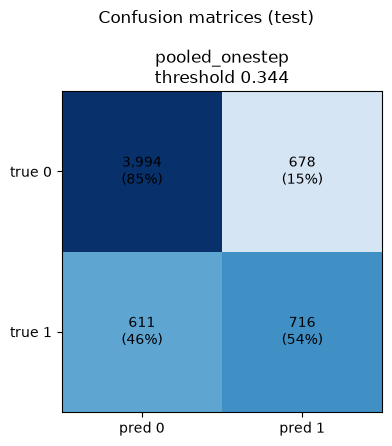

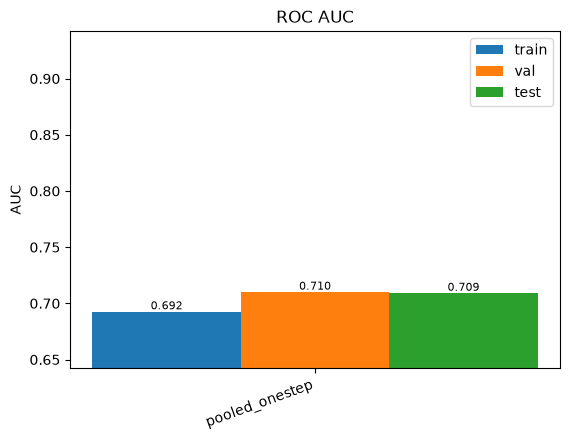

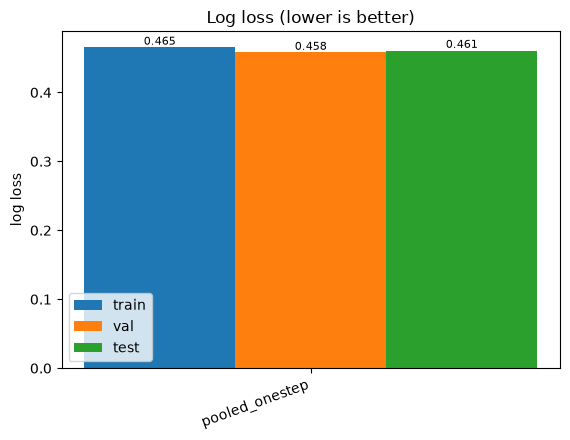

{'pooled_onestep': {'train': 0.465359809597765,
  'val': 0.45792257129597463,
  'test': 0.46078179195670793}}

In [ ]:

plot_confusion({"pooled_onestep": pooled}, split="test")
plot_auc({"pooled_onestep": pooled})
plot_logloss({"pooled_onestep": pooled})

The AUC for validation and test data is almost identical, which is a good sign that the model is not overfit. The model also has some improvements over a blanket guess at default rate.

### 3. Disadvantages of this Model



## Two Class Chain

For the next model, we will fit a separate chain for defaulters and non-defaulters and compare how the two classes behave. T
For this model the training data is seperated into default and non-default classes and a markov chain is fit to each of them 

### 1. Data and states

For each customer (`PAY_6, ..., PAY_1`) denotes their payment status and $y \in \{0, 1\}$ denotes defaults: $1$ = default next month. The state mappings send each status into a bin

$$x_t = g(\text{PAY}_t) \in \{1, \dots, K\}, \qquad \mathbf{x} = (x_1, x_2, \dots, x_T).$$

For the new two class model, we will fit it with different bins which we can then compare and see how it affects the results. I have chosen two inital data splits:
- each type of on time payment seperate, 
- combine all on time payments.

These first will give a 5 state chain while the second will only give a 4 state chain by also splitting the final state into two.

In [161]:
# ---- state mappings ----
def make_to_state(mapping, top):
    # mapping: dict raw value -> state; any raw value >= top maps to the last state
    def f(p):
        p = np.asarray(p); s = np.empty(p.shape, dtype=int)
        for raw, st in mapping.items():
            s[p == raw] = st
        s[p >= top] = max(mapping.values()) + 1 if top > max(mapping) else mapping[top]
        return s
    return f
# #function for each split of the Markov model
#original 5 states
def to_state_5full(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p >= 2] = 4
    return s

#merges -2, -1 and 0 into one state (not late)
def to_state_4nolate(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s


### 2. Fit one chain per class (train split only)
Let $\mathcal{D}_c = \{ i : y_i = c \}$ for $c \in \{0, 1\}$ and let $\alpha = 1$ be the Laplace constant.

**Initial distribution** (state in the first month):

$$\pi_c(s) = \frac{\alpha + \sum_{i \in \mathcal{D}_c} \mathbf{1}[x_{i,1} = s]}{|\mathcal{D}_c| + K\alpha}.$$

**Transition matrix** from pooled consecutive pairs:

$$N_c(a,b) = \sum_{i \in \mathcal{D}_c} \sum_{t=1}^{T-1} \mathbf{1}[x_{i,t} = a,\; x_{i,t+1} = b],$$

$$P_c(a,b) = \frac{N_c(a,b) + \alpha}{\sum_{b'} N_c(a,b') + K\alpha}, \qquad \sum_{b} P_c(a,b) = 1.$$

In [162]:
# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    #------2. Fit the Markov chain to the training data for each class (default and non-default)-------# 
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)      # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    
    #--------5. Fit a Platt scaling model to the validation set to calibrate the scores into probabilities.----------#
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m

# ---- build models ----
markov_models_1 = {
    "mk5_full":     build_markov("mk5_full",     to_state_5full,     5),
    "mk4_nolate":   build_markov("mk4_nolate",   to_state_4nolate,   4),
}

# named probability vectors, matching your existing p_mk_va / p_mk_te style
p_mk5_full_va,     p_mk5_full_te     = markov_models_1["mk5_full"]["p_va"],     markov_models_1["mk5_full"]["p_te"]
p_mk4_nolate_va,   p_mk4_nolate_te   = markov_models_1["mk4_nolate"]["p_va"],   markov_models_1 ["mk4_nolate"]["p_te"]

### 3. Sequence likelihood under each class
Assuming a first-order, time-homogeneous Markov chain:

$$\Pr(\mathbf{x} \mid y = c) = \pi_c(x_1) \prod_{t=1}^{T-1} P_c(x_t, x_{t+1}).$$

### 4. Posterior odds (Bayes' rule)
With prior $\hat{p} = \Pr(y = 1)$ estimated on train:

$$\frac{\Pr(y=1 \mid \mathbf{x})}{\Pr(y=0 \mid \mathbf{x})}
= \frac{\Pr(\mathbf{x} \mid y=1)}{\Pr(\mathbf{x} \mid y=0)} \cdot \frac{\hat{p}}{1-\hat{p}}.$$

Taking logs gives the score used in the code (`llr`):

$$s(\mathbf{x}) = \underbrace{\log\frac{\pi_1(x_1)}{\pi_0(x_1)}}_{\text{start}}
+ \sum_{t=1}^{T-1} \underbrace{\log\frac{P_1(x_t, x_{t+1})}{P_0(x_t, x_{t+1})}}_{\text{transition } t}
+ \underbrace{\log\frac{\hat{p}}{1-\hat{p}}}_{\text{prior}}.$$

Each transition contributes its log-ratio $\lambda(a,b) = \log P_1(a,b) - \log P_0(a,b)$, the quantity shown in the log-ratio heatmap. $\lambda > 0$ pushes towards default; $\lambda < 0$ pushes away.

### 5. Calibration (validation split)
The chain's independence assumptions make $s$ overconfident, so $s$ is mapped to a probability by logistic (Platt) scaling fitted on the **validation** set:

$$\Pr(y = 1 \mid \mathbf{x}) = \sigma\big(a\, s(\mathbf{x}) + b\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

If $a = 1$ and $b = 0$, this reduces to the exact Bayes posterior.

### 6. Assumptions and limitations
- **First order:** $x_{t+1}$ depends only on $x_t$, not on earlier history.
- **Time-homogeneous:** the same $P_c$ applies at every step.
- **Sparse classes:** defaulters are about 22% of the data, so $P_1$ rests on fewer transitions. Rows with small $\sum_b N_c(a,b)$ are dominated by $\alpha$.
- **Leakage control:** $\pi_c, P_c, \hat{p}$ use train only; $(a, b)$ uses validation only; test is held out for evaluation.

### 7. Matrix Heatmaps

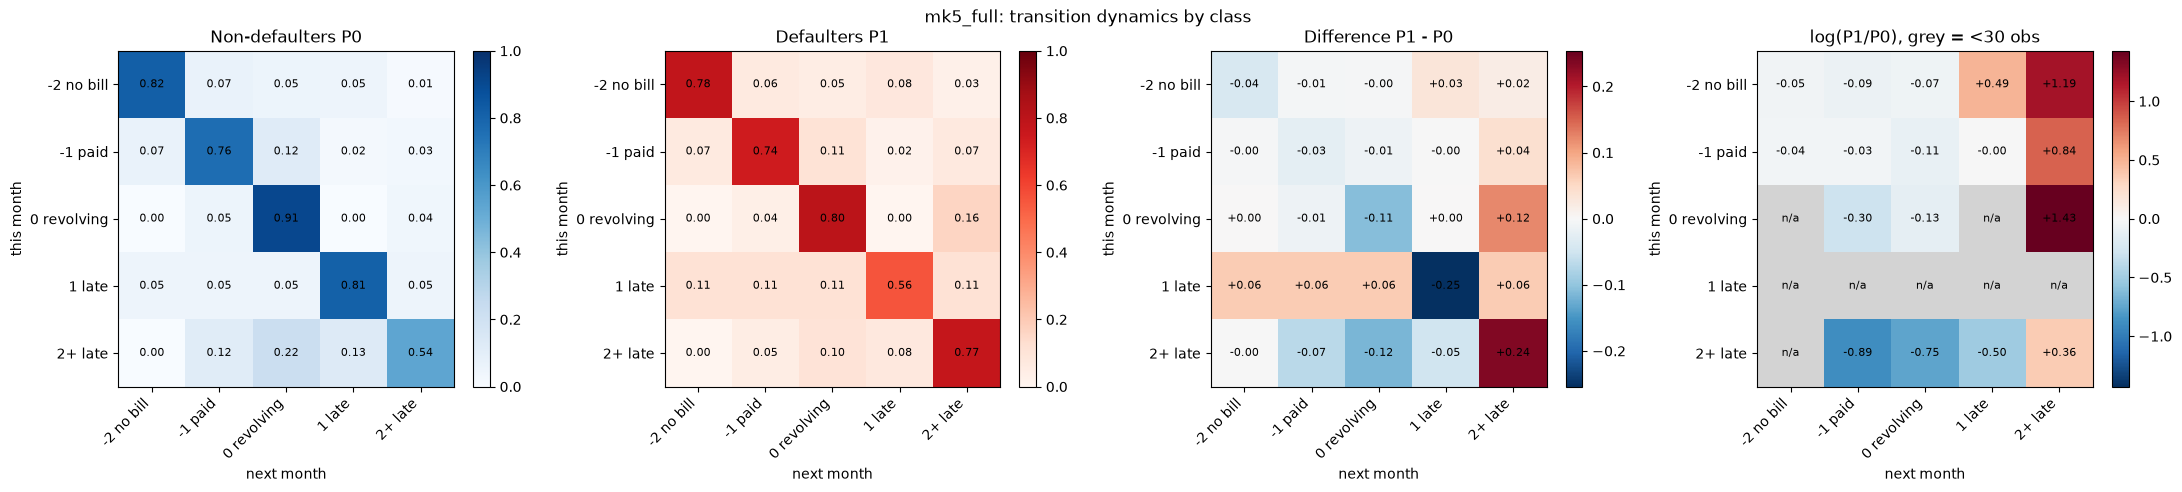

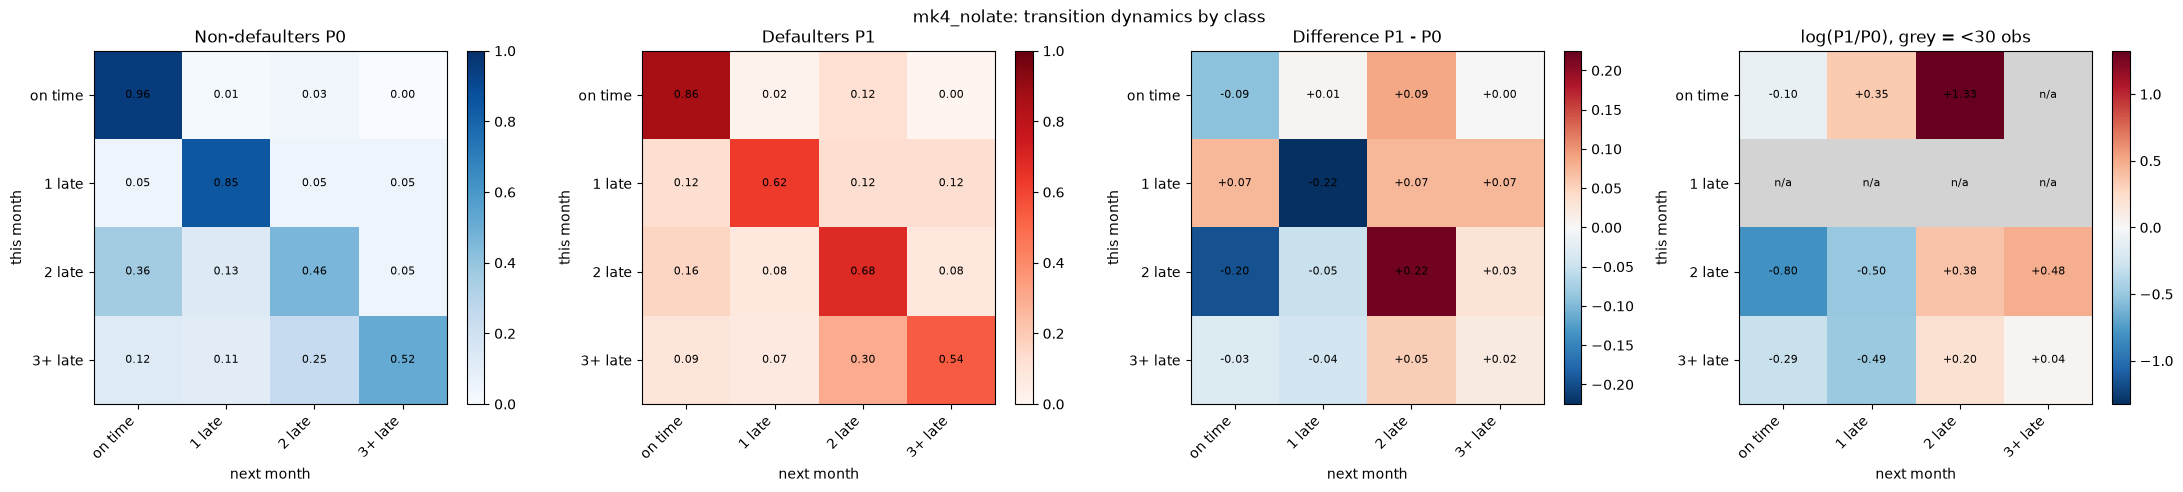

In [163]:
labels_1 = {
    "mk5_full":     ["-2 no bill", "-1 paid", "0 revolving", "1 late", "2+ late"],
    "mk4_nolate":   ["on time", "1 late", "2 late", "3+ late"],
}

def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def _prep(key, models, labels, data, pay_cols, y):
    m = models[key]; K = m["K"]
    lab = labels[key] if isinstance(labels, dict) else list(labels)
    assert len(lab) == K, f"{key}: {len(lab)} labels but K={K}"
    y = np.asarray(y)
    S = m["to_state"](data[pay_cols].values)
    C0, C1 = raw_counts(S[y == 0], K), raw_counts(S[y == 1], K)
    return m, K, lab, C0, C1

def _tick_labels(ax, lab):
    K = len(lab)
    ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=45, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(lab)
    ax.set_xlabel("next month"); ax.set_ylabel("this month")


def plot_class_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(22, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)
    P0, P1 = m["P0"], m["P1"]
    low = np.minimum(C0, C1) < min_n
    diff, logr = P1 - P0, np.log(P1) - np.log(P0)
    logr_m = np.ma.array(logr, mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr_m).max()

    fig, axs = plt.subplots(1, 4, figsize=figsize)
    panels = [(P0, "Non-defaulters P0", "Blues", 0, 1, ".2f"),
              (P1, "Defaulters P1", "Reds", 0, 1, ".2f"),
              (diff, "Difference P1 - P0", cm, -dl, dl, "+.2f"),
              (logr_m, f"log(P1/P0), grey = <{min_n} obs", cm, -ll, ll, "+.2f")]
    for ax, (M, t, cmap, lo, hi, fmt) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                txt = "n/a" if (M is logr_m and low[i, j]) else format(M[i, j], fmt)
                ax.text(j, i, txt, ha="center", va="center", fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
        _tick_labels(ax, lab)
    fig.suptitle(f"{key}: transition dynamics by class")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1, low=low)



for k in markov_models_1:
    plot_class_heatmaps(k, markov_models_1, labels_1, train, pay_cols, y_tr)



#### Interpretation of mk5
The P0 and P1 matrices both have strong diagonal enteries. Defaulters are less stable in the not late states which matches general intuition which is a good sign. The weakest P0 diagonal being the 2+ late with a value of only 0.54 Here there is a 34% chance of returning to an on time payment. This behavour is not seen in P1 which has a much stronger 0.77 diagonal entry and only a 15% chance of returning to a non late status. What is less expected is the non defaulters are more likely to remain 1 month over than defaulters. This result is likely an artifact of smoothing due to the limited data size of the 1 late row.

#### Interpretation of mk4
A similar issue arrises in this split which further reinforces the fact that it is a problem caused by the data. To investivage this we can take a look at the raw counts for each transition matrix and flag any with very few transitions.

### 8. Count Heatmaps

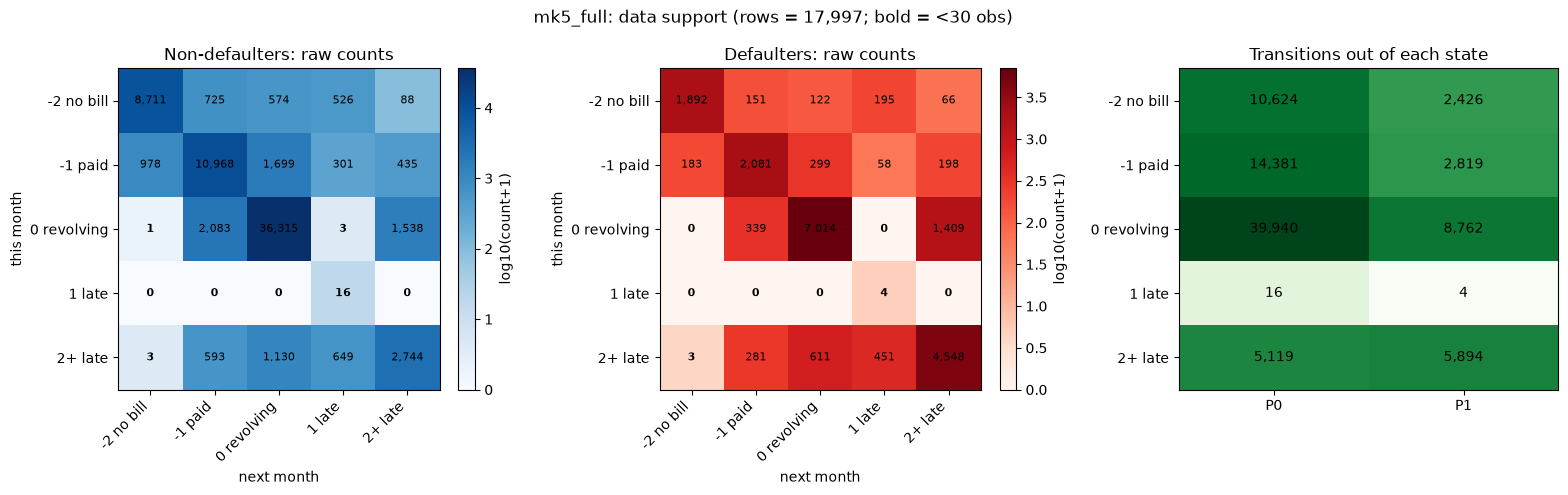

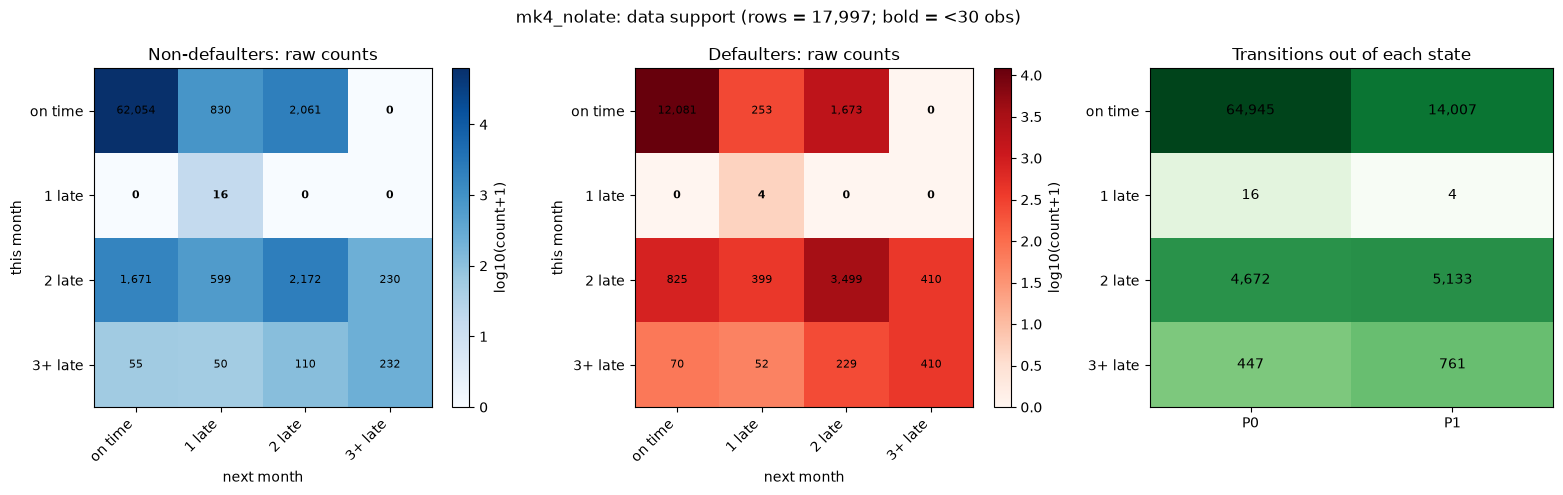

In [164]:
MIN_N = 30  # cells with fewer raw transitions than this are flagged as unreliable

def plot_count_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(16, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)

    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for ax, C, t, cmap in [(axs[0], C0, "Non-defaulters: raw counts", "Blues"),
                           (axs[1], C1, "Defaulters: raw counts", "Reds")]:
        im = ax.imshow(np.log10(C + 1), cmap=cmap); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, f"{C[i, j]:,}", ha="center", va="center", fontsize=8,
                        fontweight="bold" if C[i, j] < min_n else "normal")
        plt.colorbar(im, ax=ax, fraction=0.046).set_label("log10(count+1)")
        _tick_labels(ax, lab)

    row_n = np.vstack([C0.sum(1), C1.sum(1)]).T
    axs[2].imshow(np.log10(row_n + 1), cmap="Greens", aspect="auto")
    for i in range(K):
        for c in range(2):
            axs[2].text(c, i, f"{row_n[i, c]:,}", ha="center", va="center")
    axs[2].set_xticks([0, 1]); axs[2].set_xticklabels(["P0", "P1"])
    axs[2].set_yticks(range(K)); axs[2].set_yticklabels(lab)
    axs[2].set_title("Transitions out of each state")

    fig.suptitle(f"{key}: data support (rows = {len(data):,}; bold = <{min_n} obs)")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1)

for k in markov_models_1:
    plot_count_heatmaps(k, markov_models_1, labels_1, train, pay_cols, y_tr)

This count cell clearly displays the data issue. The simplest way to get around this issue is to shift the boundaries of the states so state 1 is absorbed by another. It is not obvious exactly which way would be best to split the data. For the 5 state chain we could either:
- merge 1 into 2+, 
- make a 1-2 and a 3+ state, 
- or merge 1 and 0. 

Merging 1 and 0 seems the least reasonable choice as you are putting an on time payment with a late payment. We can calculate different splits and see how it each change affects the performance.

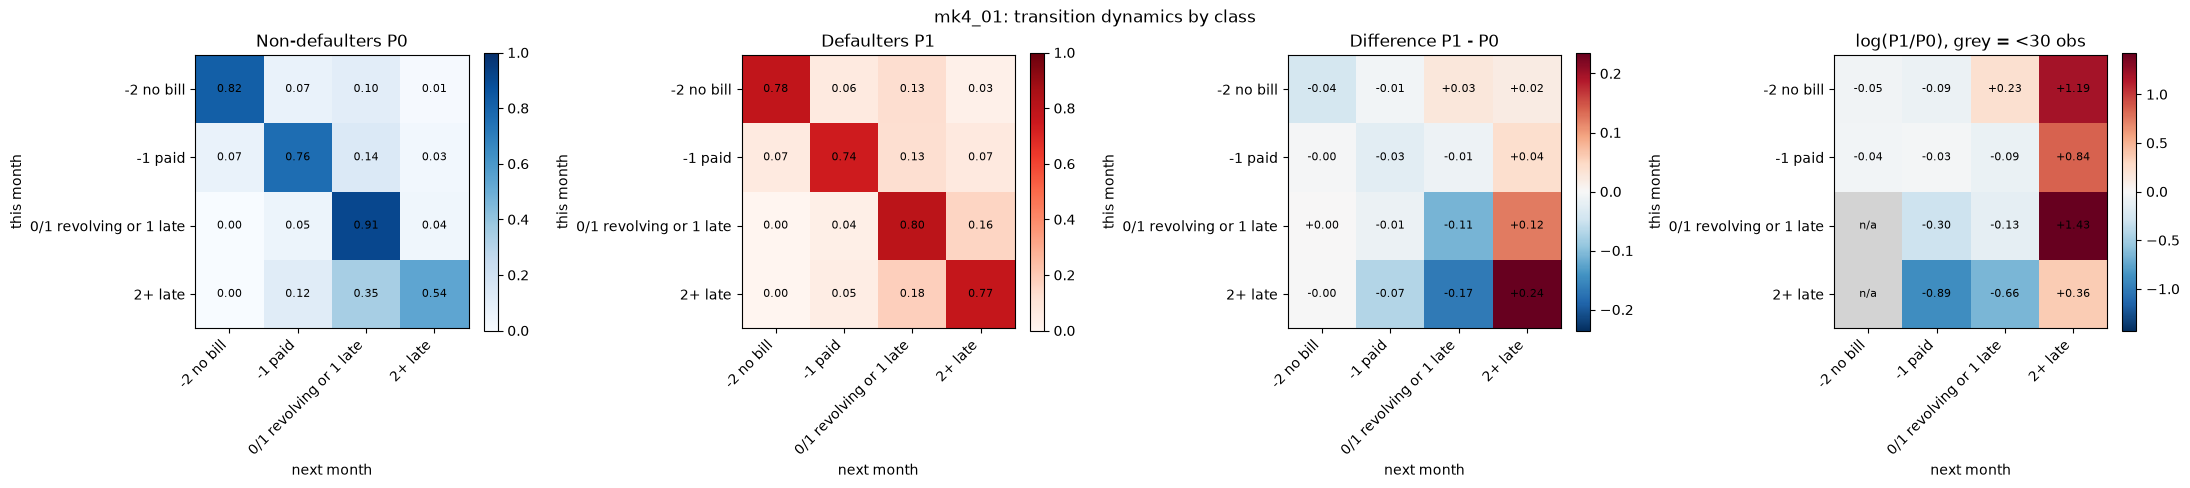

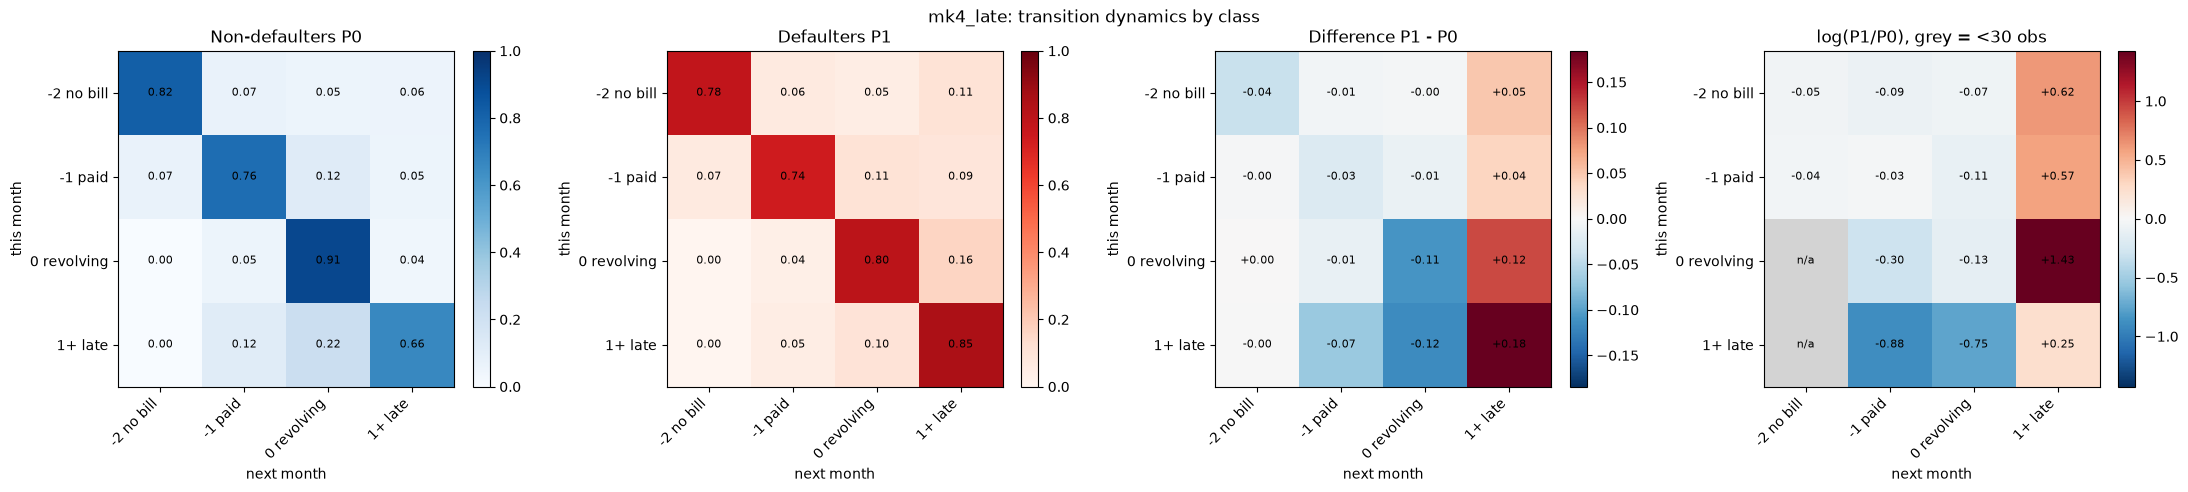

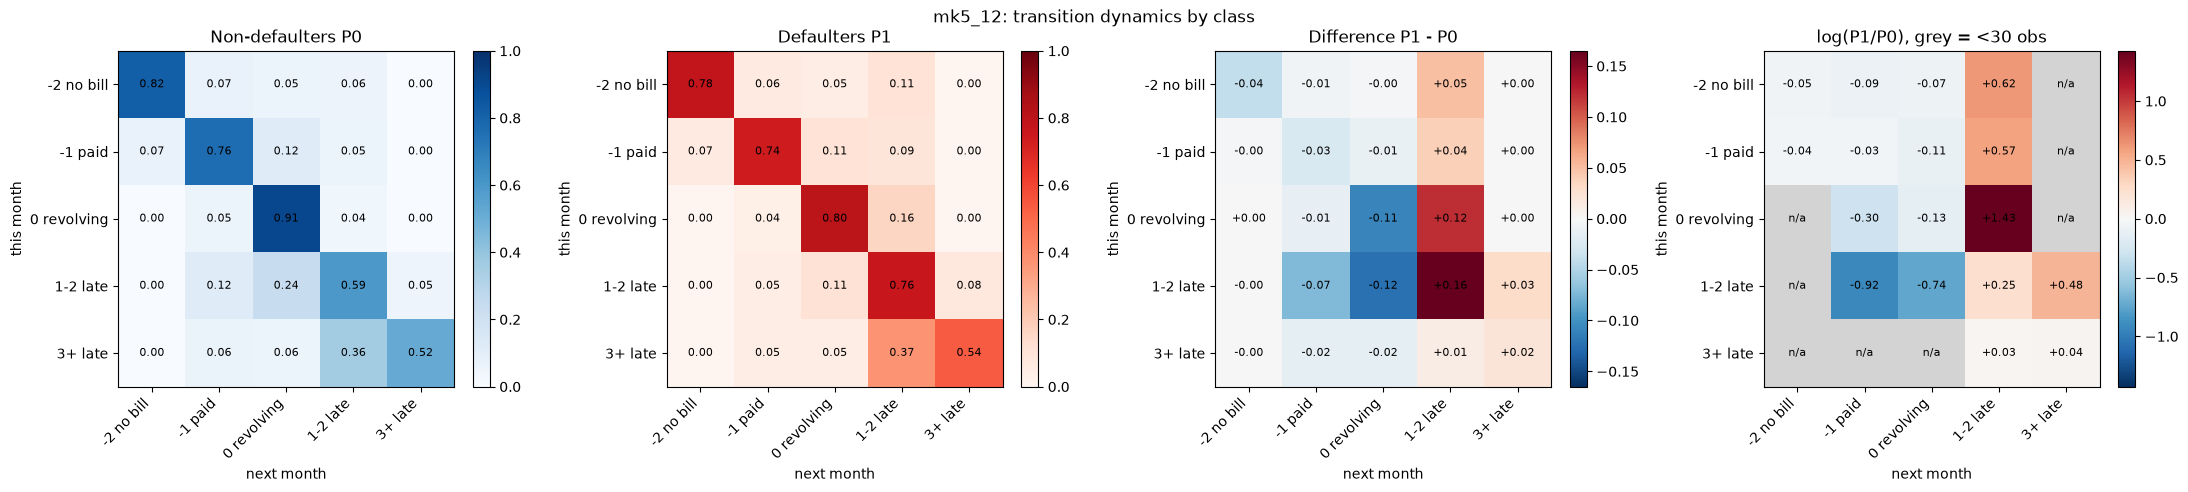

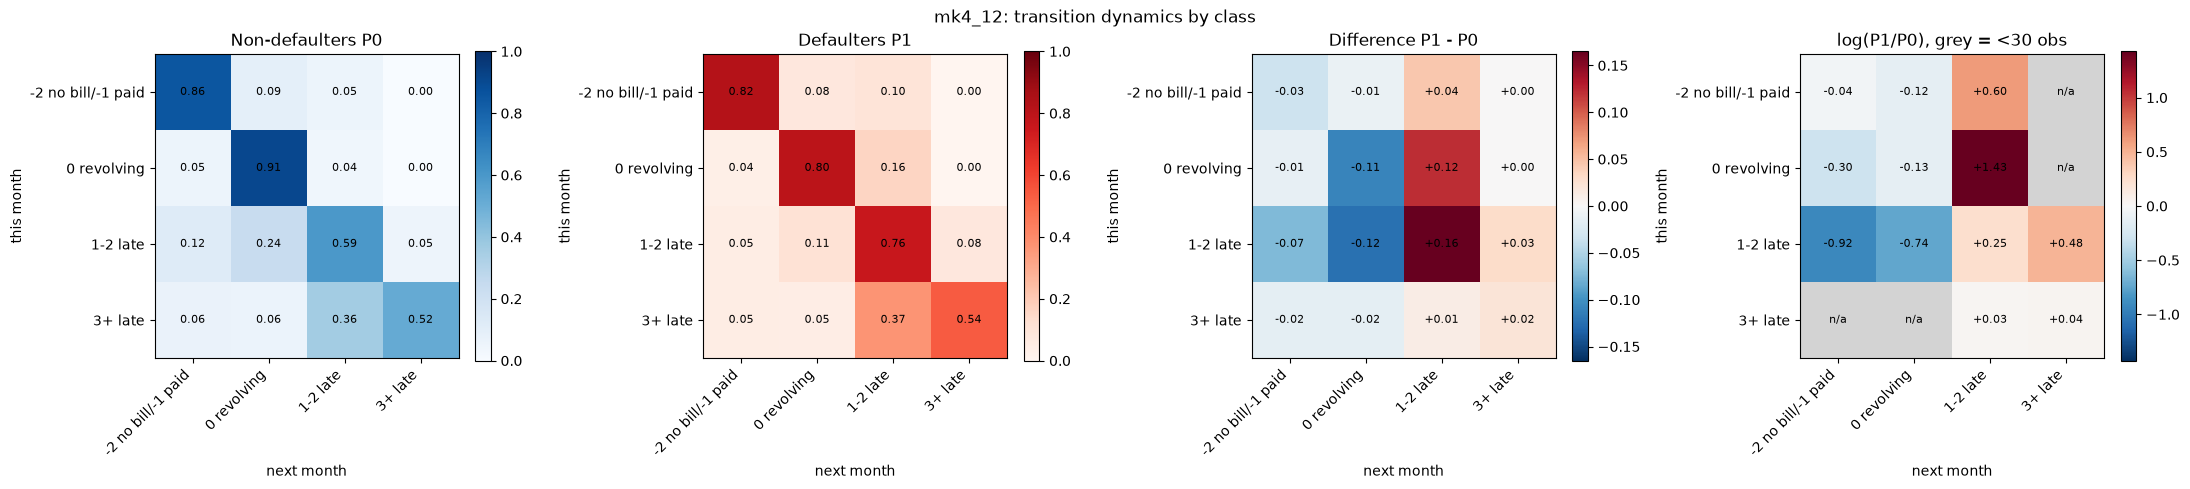

In [165]:
#new bins:
#merge 0 and 1
def to_state_4_01(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 2; s[p >= 2] = 3
    return s
#merge 1 and 2
def to_state_5_12(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p == 1] = 3; s[p == 2] = 3; s[p >= 3] = 4
    return s
#all late states are merged into one state
def to_state_4_late(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 1; s[p == 0] = 2; s[p >= 1] = 3
    return s
#merge 1 and 2 into one state and -2 and -1 into one state
def to_state_4_12(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p == -2] = 0; s[p == -1] = 0; s[p == 0] = 1; s[p == 1] = 2; s[p == 2] = 2; s[p >= 3] = 3
    return s
markov_models_2 = {
    "mk4_01":     build_markov("mk4_01",     to_state_4_01,     4),
    "mk4_late":   build_markov("mk4_late",   to_state_4_late,   4),
    "mk5_12":   build_markov("mk5_12",   to_state_5_12,   5),
    "mk4_12":   build_markov("mk4_12",   to_state_4_12,   4),
}
labels2 = {
    "mk4_01":   ["-2 no bill", "-1 paid", "0/1 revolving or 1 late", "2+ late"],
    "mk4_late": ["-2 no bill", "-1 paid", "0 revolving", "1+ late"],
    "mk5_12":   ["-2 no bill", "-1 paid", "0 revolving", "1-2 late", "3+ late"],
    "mk4_12":  ["-2 no bill/-1 paid", "0 revolving", "1-2 late", "3+ late"],
}
for k in markov_models_2:
    plot_class_heatmaps(k, markov_models_2, labels2, train, pay_cols, y_tr)
    #plot_count_heatmaps(k, markov_models_2, labels2, train, pay_cols, y_tr)

compare metrics, note states which on the surface might not be adding much information, pick one of these as the best after looking at performance, then make 2 smaller matrices and compare them to see if it makes a difference - computation less with same information in the end 

### Comparison

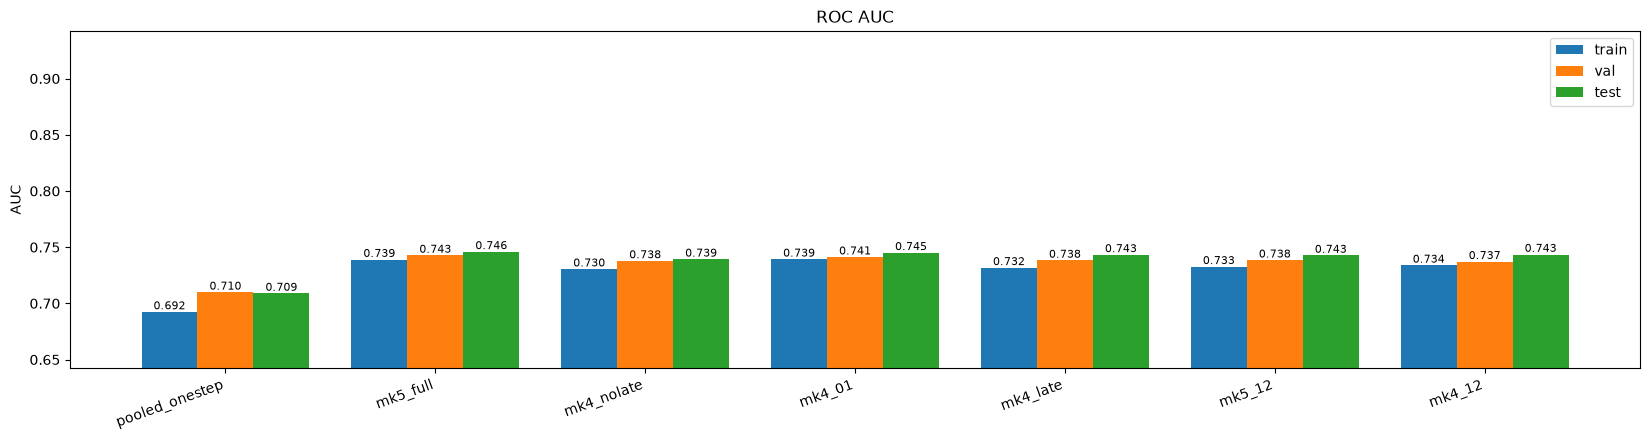

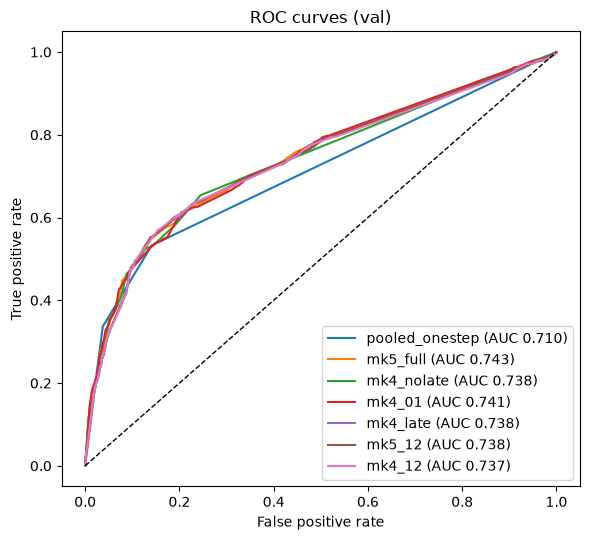

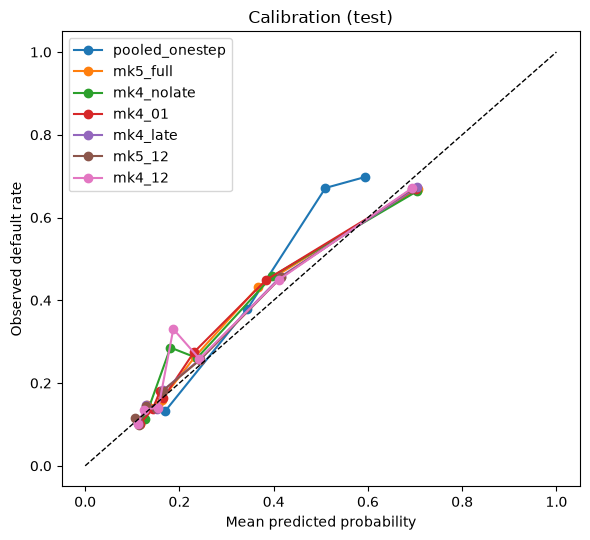

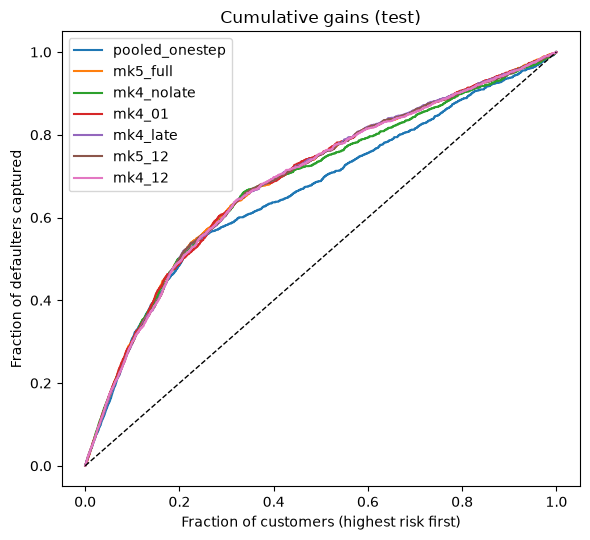

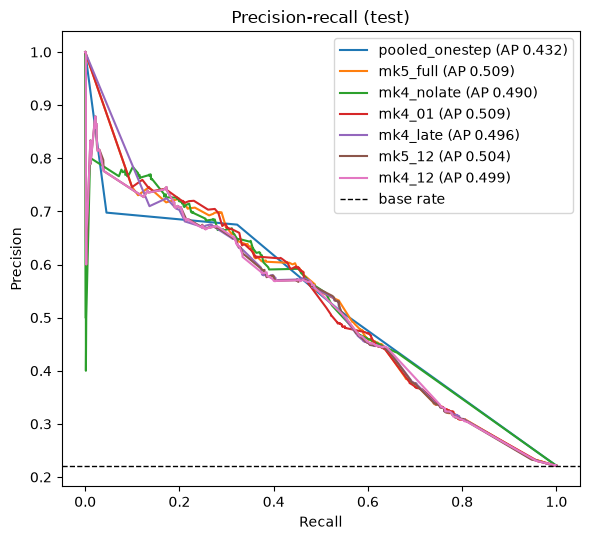

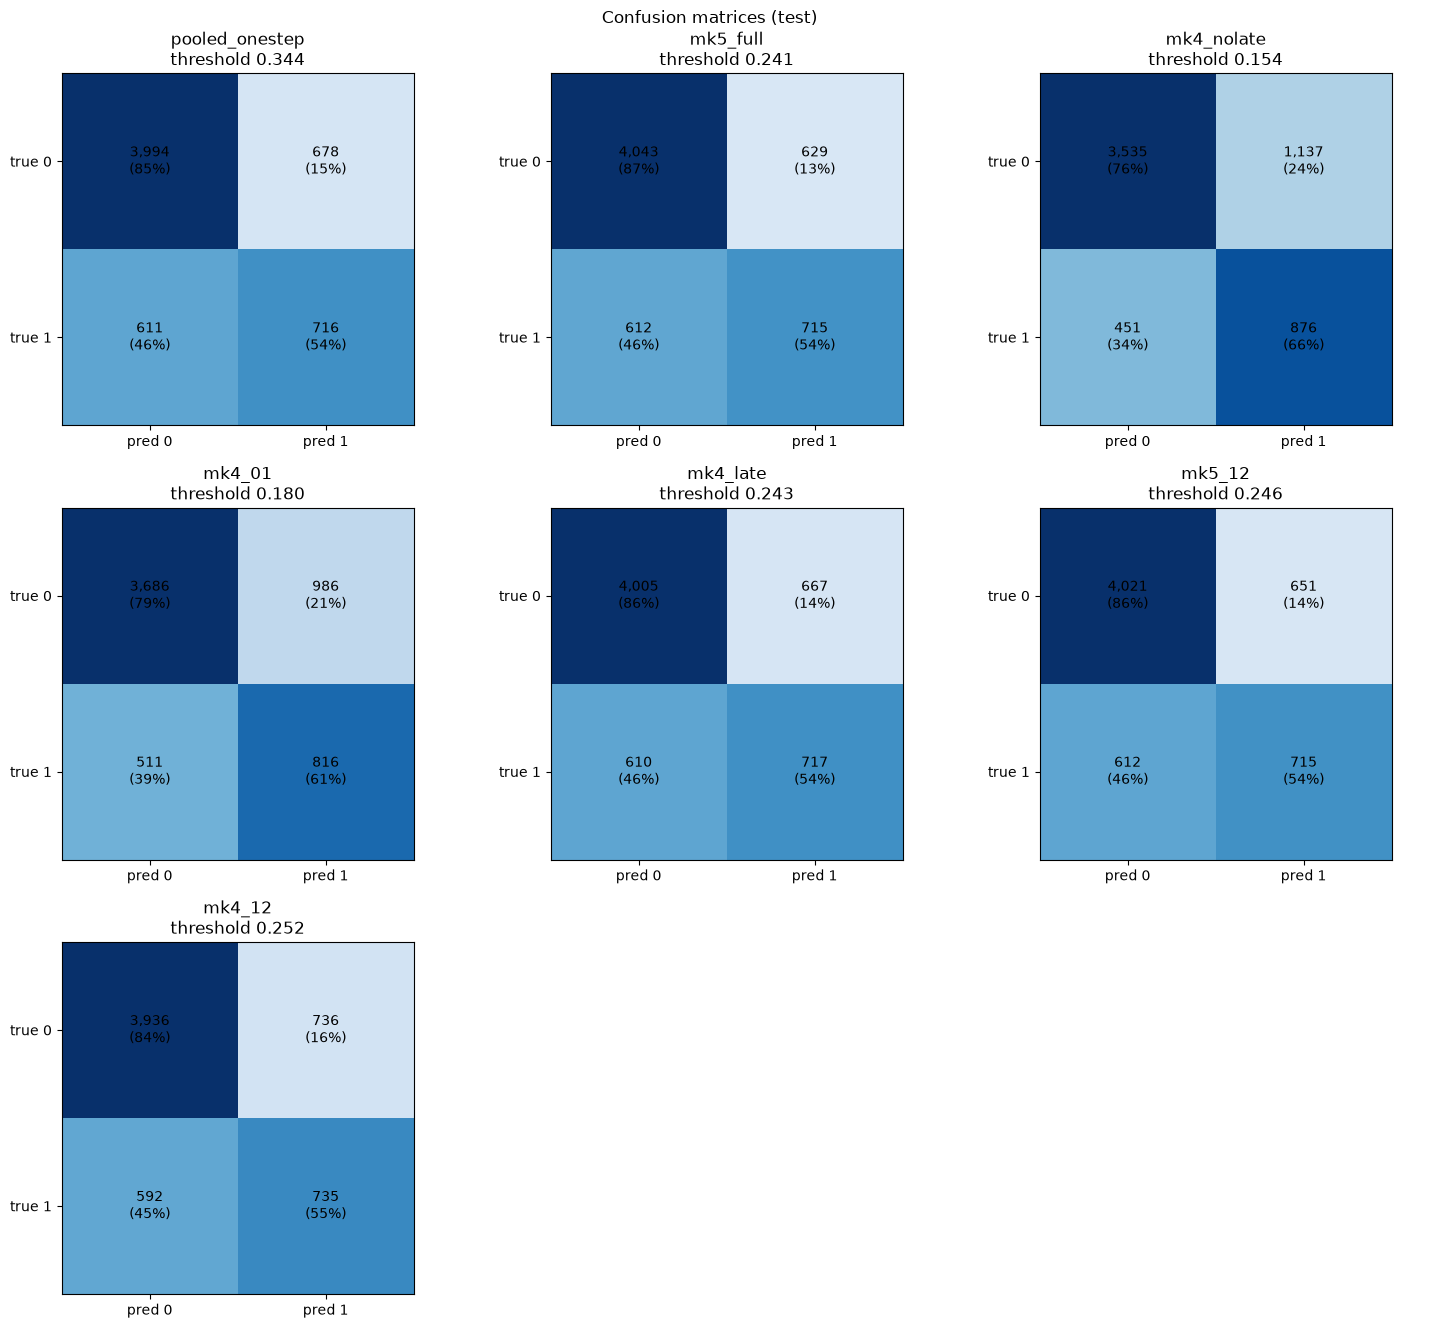

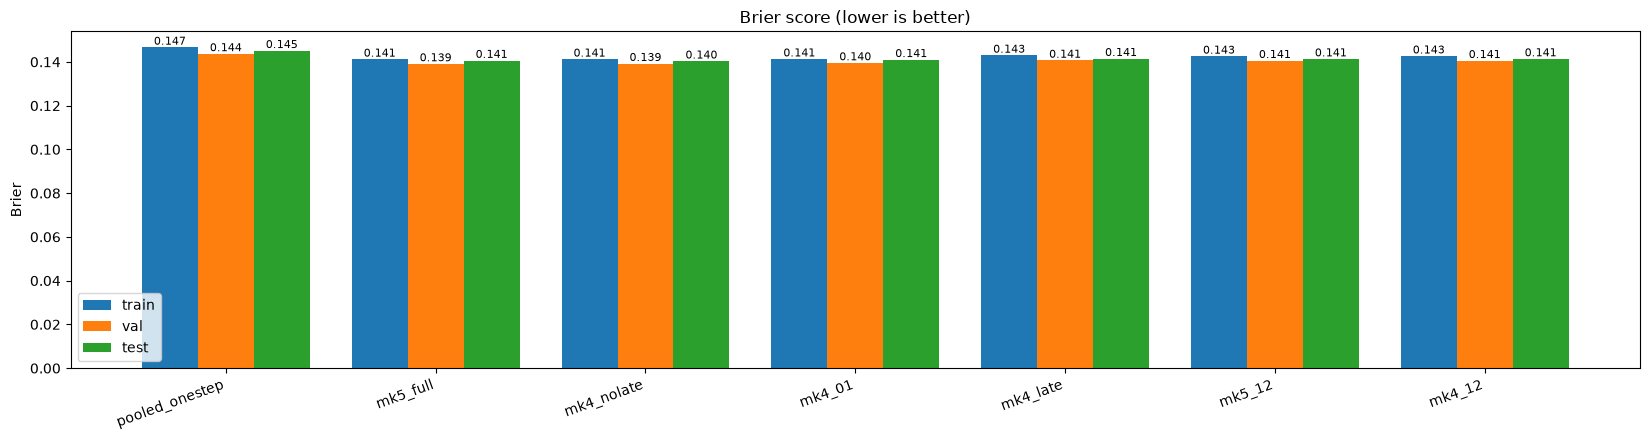

{'pooled_onestep': {'train': 0.14663098983026626,
  'val': 0.143655480785539,
  'test': 0.14509598430349793},
 'mk5_full': {'train': 0.14116744517591637,
  'val': 0.1390516589639698,
  'test': 0.14059921268115233},
 'mk4_nolate': {'train': 0.1411871795581634,
  'val': 0.13919579294603016,
  'test': 0.14029910331087525},
 'mk4_01': {'train': 0.14126220942965534,
  'val': 0.1395035943552968,
  'test': 0.1409785889681379},
 'mk4_late': {'train': 0.14296889121351097,
  'val': 0.14066904538680325,
  'test': 0.14145655219938447},
 'mk5_12': {'train': 0.142522168660528,
  'val': 0.1405486236530231,
  'test': 0.1412856166056028},
 'mk4_12': {'train': 0.1426080233056861,
  'val': 0.14053432409435862,
  'test': 0.1413350753122839}}

In [168]:
compare = {"pooled_onestep": pooled, **markov_models_1, **markov_models_2}
plot_auc(compare)
plot_roc(compare, split="val")
plot_calibration(compare, split="test")
plot_gains(compare)
plot_pr(compare)
plot_confusion(compare, split="test")
plot_brier(compare)